<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# Multi Logistic Regression

In the class dedicated to logistic regression, you have learned how we can model binary classification problems with a linear decision boundary using the sigmoid function.

As we have discussed, through a linear decision boundary we can model relatively simple problems, where the relationship between the input variables and the output class has an (almost) linear relationship. However, what happens when we need to model problems where the input-output relationship is not linear?

Although logistic regression offers relatively simple solutions (polynomial features), their application is somewhat more complex. Polynomial features grow exponentially as the number of input dimensions increases, and deciding which ones to use is not trivial. Let's consider an input image, whose input dimensions coincide with the number of pixels (>10,000 for a relatively small image).

To understand how a neural network learns, we are going to carry out this practical exercise in which we will combine several logistic regressions like those you worked on in the previous class.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np


We begin by working with a small dataset with two input variables ($d=2$).

In [2]:
X, y = make_circles(n_samples=1000, noise=0.1, factor=0.5, random_state=42)

X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float().unsqueeze(1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

If we now visualize the distribution of the two classes, we indeed confirm that the problem we are facing is non-linear. In fact, we can see that the samples belonging to the yellow class have values close to 0 (both positive and negative) in both feature 1 and feature 2; while the samples of the purple class have higher values (in absolute value) in both features. In summary, a simple but linearly non-separable problem.

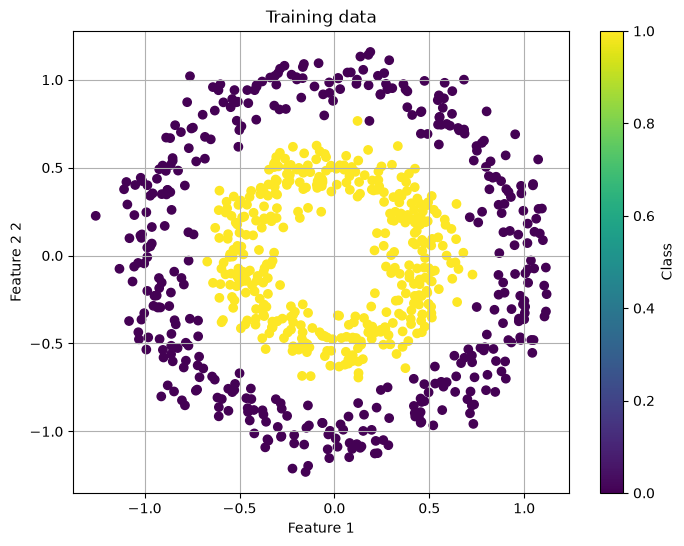

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.squeeze(), cmap='viridis', marker='o')
plt.title('Training data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2 2')
plt.colorbar(label='Class')
plt.grid(True)
plt.show()

Next, you have available an adaptation of logistic regression using the nn.Module in the model's implementation. As we have seen, when we create a model that inherits from nn.Module, we must implement the constructor (\_\_init\_\_) and the forward method. Furthermore, we will specify that variables $W$ and $b$ are parameters of the model and that, therefore, they must be learned through gradient descent.

In [4]:
class LogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super(LogisticRegression, self).__init__()
        # Initialization of W and b. W is initialized with (normal)random integers, while bias is set to zero.
        self.W = nn.Parameter(torch.randn(input_dim, 1))
        self.b = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        # Calculation of affine transformacion and sigmoid output
        return torch.sigmoid(torch.mm(x, self.W) + self.b)

Here is a training loop function that uses a PyTorch optimizer for learning the parameters. As we specified in the model that $W$ and $b$ were of type nn.Parameter, now we only need to specify model.parameters() so that the optimizer takes care of these parameters (as opposed to specifying them implicitly if we don't use nn.Parameter).

In [5]:
def train_model(model, X_train, y_train, epochs=1000, lr=0.1):

    criterion = nn.BCELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    for epoch in range(epochs):


        # Forward pass
        y_pred = model(X_train)

        # Cálculo de la pérdida
        loss = criterion(y_pred, y_train)

        # Backward pass y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch+1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')



Create a logistic regression model and train it for 1000 iterations with a learning rate of 0.1


In [6]:
iterations = 1000
lr = 0.1

model = LogisticRegression(X_train.shape[1])
train_model(model, X_train, y_train, epochs=iterations, lr=lr)

Epoch [100/1000], Loss: 0.6977
Epoch [200/1000], Loss: 0.6939
Epoch [300/1000], Loss: 0.6931
Epoch [400/1000], Loss: 0.6929
Epoch [500/1000], Loss: 0.6929
Epoch [600/1000], Loss: 0.6929
Epoch [700/1000], Loss: 0.6929
Epoch [800/1000], Loss: 0.6929
Epoch [900/1000], Loss: 0.6929
Epoch [1000/1000], Loss: 0.6929


To facilitate the visualization of the decision boundary, here is a function to visualize not only the decision boundary but also the properly classified samples (in blue and red).


In [7]:

def plot_decision_boundary(model, X, y):
    model.eval()
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    grid_tensor = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()]).float()
    Z = model(grid_tensor)
    Z = Z.detach().numpy().reshape(xx.shape)

    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=1)

    y_pred_probs = model(X)
    y_pred_classes = (y_pred_probs > 0.5).float()

    plt.scatter(X[:, 0], X[:, 1], c=y_pred_classes.squeeze(), cmap=plt.cm.coolwarm, edgecolors='k') # Usar coolwarm para los puntos coloreados por predicción
    plt.title("Decission boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

Visualize the boundary and observe that the model has trained a **linear** decision boundary.


/tmp/ipykernel_400362/2127035783.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_400362/2127035783.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


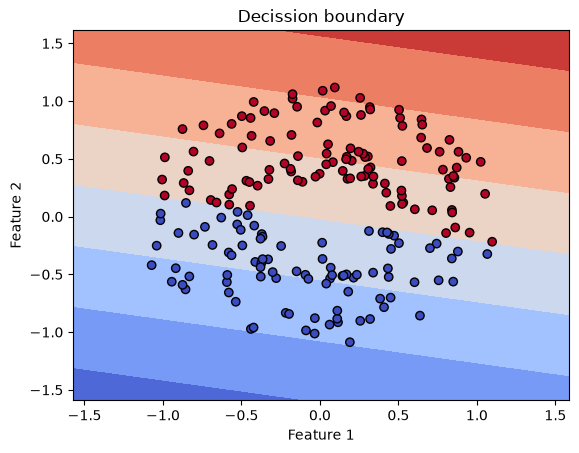

In [8]:
plot_decision_boundary(model, X_test, y_test)

Now is the time to use multiple logistic regressions to model **non-linear** problems. To do this, create a class called `MultiLogisticRegression`. Then, follow the instructions:

* **Constructor `__init__`**: It will receive two variables, `input_dim`, which indicates the number of input variables, and `num_neurons`, which specifies how many logistic regressions we are going to train in parallel. In the constructor, you must instantiate as many objects of the `LogisticRegression` class as indicated by `num_neurons`, and you must store them in an `nn.ModuleList`. In addition, the model will instantiate a new `LogisticRegression` (called `output`) whose `input_dim` will be the number of neurons in the list.

* **Method `forward`**: Given `X`, you must pass the training dataset to each of the logistic regressions and concatenate each of their outputs (you can use `torch.cat`) until forming a new matrix of dimensions `n x num_neurons`. Once this intermediate output is generated, we pass it through the `output` logistic regression.

Once implemented, create a `MultiLogisticRegression` model with `num_neurons = 3`. Train it for 15,000 epochs with a learning rate of 0.1. Finally, visualize the decision boundary.


In [9]:
class MultiLogisticRegression(nn.Module):
    def __init__(self, input_dim, num_neurons):
        super(MultiLogisticRegression, self).__init__()
        self.neuron_list = nn.ModuleList([LogisticRegression(input_dim) for _ in range(num_neurons)])
        self.output = LogisticRegression(num_neurons)
        
    def forward(self, x):
        neuron_outputs = []
        for regresion in self.neuron_list:
            neuron_outputs.append(regresion(x))

        intermediate_output = torch.cat(neuron_outputs, dim=1)
        out = self.output(intermediate_output)
        return out
        

In [10]:
num_neurons = 3
epochs = 15000 
lr = 0.1

multi_logistic_model = MultiLogisticRegression(X_train.shape[1], num_neurons)
train_model(multi_logistic_model, X_train, y_train, epochs=epochs, lr=lr)

Epoch [100/15000], Loss: 0.6969
Epoch [200/15000], Loss: 0.6944
Epoch [300/15000], Loss: 0.6925
Epoch [400/15000], Loss: 0.6909
Epoch [500/15000], Loss: 0.6896
Epoch [600/15000], Loss: 0.6884
Epoch [700/15000], Loss: 0.6873
Epoch [800/15000], Loss: 0.6861
Epoch [900/15000], Loss: 0.6849
Epoch [1000/15000], Loss: 0.6836
Epoch [1100/15000], Loss: 0.6821
Epoch [1200/15000], Loss: 0.6805
Epoch [1300/15000], Loss: 0.6786
Epoch [1400/15000], Loss: 0.6765
Epoch [1500/15000], Loss: 0.6741
Epoch [1600/15000], Loss: 0.6712
Epoch [1700/15000], Loss: 0.6679
Epoch [1800/15000], Loss: 0.6642
Epoch [1900/15000], Loss: 0.6599
Epoch [2000/15000], Loss: 0.6550
Epoch [2100/15000], Loss: 0.6495
Epoch [2200/15000], Loss: 0.6434
Epoch [2300/15000], Loss: 0.6368
Epoch [2400/15000], Loss: 0.6298
Epoch [2500/15000], Loss: 0.6224
Epoch [2600/15000], Loss: 0.6148
Epoch [2700/15000], Loss: 0.6070
Epoch [2800/15000], Loss: 0.5991
Epoch [2900/15000], Loss: 0.5914
Epoch [3000/15000], Loss: 0.5838
Epoch [3100/15000],

/tmp/ipykernel_400362/2127035783.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_400362/2127035783.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


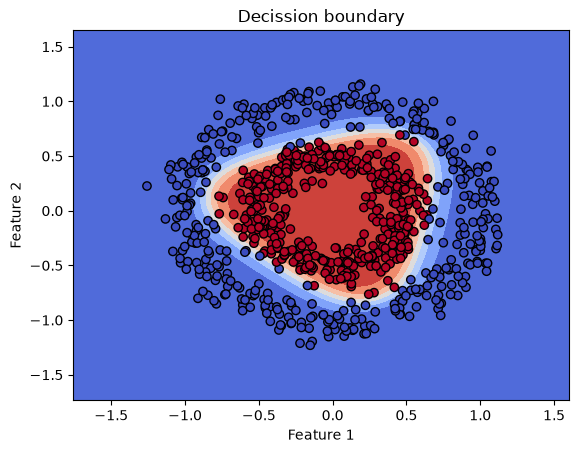

In [11]:
plot_decision_boundary(multi_logistic_model, X_train, y_train)

To understand exactly how the `MultiLogisticRegression` model has worked, draw the decision boundary of each of the logistic regressions that make up the `MultiLogisticRegression`. In the following code, you can make a copy of each of the **neurons**.


/tmp/ipykernel_400362/2127035783.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_400362/2127035783.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


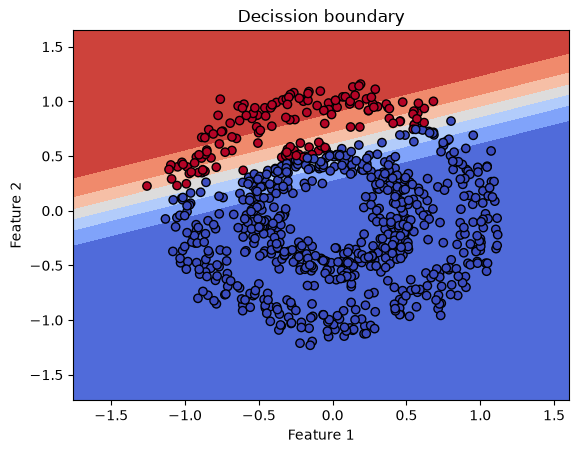

In [12]:
# assume multi_logistic_model.neuron_list
regression_1 = LogisticRegression(input_dim=2)
regression_1.load_state_dict(multi_logistic_model.neuron_list[0].state_dict())

plot_decision_boundary(regression_1, X_train, y_train)

/tmp/ipykernel_400362/2127035783.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_400362/2127035783.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


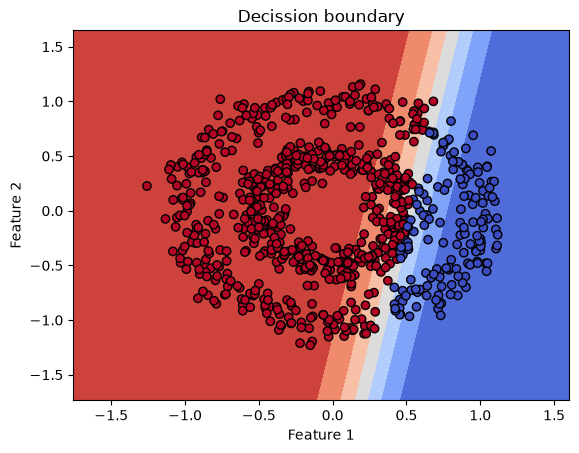

In [13]:
# assume multi_logistic_model.neuron_list
regression_2 = LogisticRegression(input_dim=2)
regression_2.load_state_dict(multi_logistic_model.neuron_list[1].state_dict())

plot_decision_boundary(regression_2, X_train, y_train)

/tmp/ipykernel_400362/2127035783.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_400362/2127035783.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


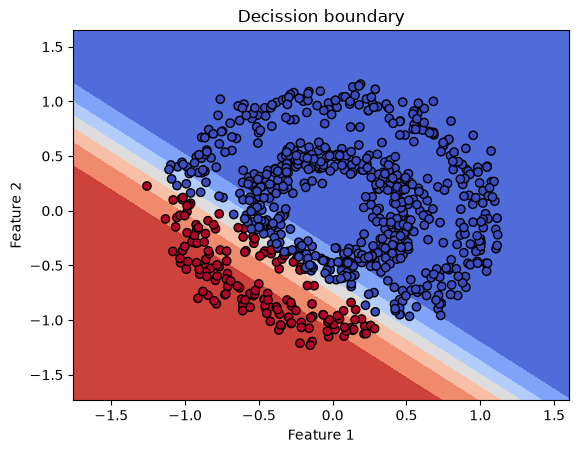

In [14]:
# assume multi_logistic_model.neuron_list
regression_3 = LogisticRegression(input_dim=2)
regression_3.load_state_dict(multi_logistic_model.neuron_list[2].state_dict())

plot_decision_boundary(regression_3, X_train, y_train)

Once we’ve understood what each of the neurons is doing individually, we can more easily grasp how a very **primitive neural network** works. In the example we’re working with, the 3 logistic regressions operating in parallel are transforming the input space (which is 2-dimensional and where the samples are not linearly separable) into a new space (3-dimensional) where they **can** be separated.

To visualize this, here’s an example of code that allows us to display and manipulate a dataset in **3D**. All you need to do is generate the `intermediate_outputs` matrix (n x 3) by concatenating the outputs from the three logistic regressions (which we’ve previously separated).


In [15]:
##
# intermediate_outputs = #list of outputs of X_train into each regression and concatenated
intermediate_outputs = torch.cat((regression_1(X_train), regression_2(X_train), regression_3(X_train)), dim=1)

y_train_np = y_train.detach().numpy()

In [18]:
import plotly.graph_objects as go


##assume intermediate_outputs of size nx3 (in numpy)
##asume y_train_np list of output classes (in numpy)
# Detach tensor from computational graph and convert to NumPy
if hasattr(intermediate_outputs, 'detach'):
    intermediate_outputs = intermediate_outputs.detach().cpu().numpy()

# Ensure y_train_np is also detached/converted if it's a PyTorch Tensor
if hasattr(y_train_np, 'detach'):
    y_train_np = y_train_np.detach().cpu().numpy()

fig = go.Figure(data=[go.Scatter3d(x=intermediate_outputs[:,0], y=intermediate_outputs[:,1], z=intermediate_outputs[:,2],mode='markers',
                                   marker=dict(
                                       size=5,
                                       color=y_train_np.flatten(),  # Aquí se colorean según la clase
                                       colorscale='Viridis',  # Puedes cambiar el mapa de colores
                                       colorbar=dict(title='Clase'),  # Muestra la leyenda
                                       opacity=0.8))])
fig.show(renderer="iframe")